# PHM North America 2024 Conference Data Challenge
## Helicopter Turbine Engine Health Estimation


**Course:** AI in Industry —  Project (6+3 CFU)

---

### Problem Recap
We are given operating-condition sensor readings for helicopter turbine engines and must predict two things per observation:

1. **`trq_margin`** (regression) — the torque margin (%), a continuous health indicator.
2. **`faulty`** (classification) — binary health state (0 = nominal, 1 = faulty), **with a confidence score**.

### Our Architecture (2-Stage, Physics-Informed + Probabilistic)

```
Raw sensors  ──►  [STAGE 1: Regression]  ──►  predicted trq_margin (+ uncertainty)
     │                                                │
     └───────────────────────┬────────────────────────┘
                              ▼
                  [STAGE 2: Classification]
                              │
                              ▼
                 faulty label + confidence
```

**Why this design?** `trq_margin` is a physically meaningful residual (measured vs. expected torque).
Predicting it first, then feeding the prediction *and* its uncertainty into the classifier, lets the
classifier "see" the health signal explicitly instead of re-deriving it from scratch.


## 1. Environment Setup


In [ ]:
# Install libraries not preinstalled on Colab (safe to re-run)
!pip install -q lightgbm xgboost shap scikit-learn --upgrade


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.5/3.5 MB 43.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 102.0 MB/s eta 0:00:00


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                              accuracy_score, roc_auc_score, f1_score,
                              confusion_matrix, classification_report)
from sklearn.inspection import permutation_importance
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import fbeta_score
from scipy.stats import spearmanr
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant
from scipy import stats

import lightgbm as lgb
import xgboost as xgb
import shap

pd.set_option('display.max_columns', None)
np.random.seed(42)


## 2. Load Data

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

DATA_DIR = '/content/drive/MyDrive/Phm'

X = pd.read_csv(f'{DATA_DIR}/X_train.csv')
y = pd.read_csv(f'{DATA_DIR}/y_train.csv')

print('X shape:', X.shape)
print('y shape:', y.shape)

# Sanity check: ids must align 1:1 before merging
assert (X['id'].values == y['id'].values).all(), "id mismatch between X and y!"

df = X.merge(y, on='id')
df.head()


Mounted at /content/drive
X shape: (742625, 8)
y shape: (742625, 3)


,id,trq_measured,oat,mgt,pa,ias,np,ng,faulty,trq_margin
0,0,54.100,2.00000,544.5000,212.1408,74.56250,89.18000,99.6400,1,-13.717745
1,1,49.625,24.22231,578.4844,1625.6400,30.35596,99.55273,91.3866,0,1.791863
2,2,52.000,7.00000,566.1000,1912.9250,65.62500,100.14000,90.9600,1,-13.944871
3,3,62.400,7.25000,560.1000,277.0632,54.81250,90.64000,100.2800,0,-0.017281
4,4,62.900,23.25000,593.7000,53.6448,73.43750,99.91000,92.1700,0,7.322404


## 3. Exploratory Data Analysis (EDA)

Goal: understand feature ranges, correlations, class balance, and the relationship between
`trq_margin` and `faulty` **before** building any model

In [ ]:
print('--- Missing values ---')
print(df.isna().sum())
print()
print('--- Class balance (faulty) ---')
print(df['faulty'].value_counts(normalize=True).rename('proportion'))
print()
print('--- Descriptive stats ---')
df.describe().T


--- Missing values ---
id              0
trq_measured    0
oat             0
mgt             0
pa              0
ias             0
np              0
ng              0
faulty          0
trq_margin      0
dtype: int64

--- Class balance (faulty) ---
faulty
0    0.596811
1    0.403189
Name: proportion, dtype: float64

--- Descriptive stats ---


,count,mean,std,min,25%,50%,75%,max
id,742625.0,371312.000000,214377.516165,0.000000,185656.000000,371312.000000,556968.000000,742624.000000
trq_measured,742625.0,65.097549,13.253672,14.673340,56.100000,65.700000,75.500000,104.730500
oat,742625.0,12.675167,8.066084,-19.250000,7.500000,13.703440,18.500000,36.799130
mgt,742625.0,592.246116,39.654582,467.300000,562.400000,589.400000,622.300000,723.400000
pa,742625.0,511.776065,563.190555,-208.389200,135.331200,340.461600,588.264000,3097.510000
ias,742625.0,79.324591,35.395075,0.000000,51.125000,88.375000,110.562500,137.562500
np,742625.0,97.377919,3.996721,85.010000,95.330000,99.759770,100.020000,101.560000
ng,742625.0,95.517281,3.635084,90.001830,92.226440,94.810000,99.900000,101.220000
faulty,742625.0,0.403189,0.490538,0.000000,0.000000,0.000000,1.000000,1.000000
trq_margin,742625.0,-1.157346,14.068843,-74.747111,-6.604321,1.693847,7.785348,34.148857


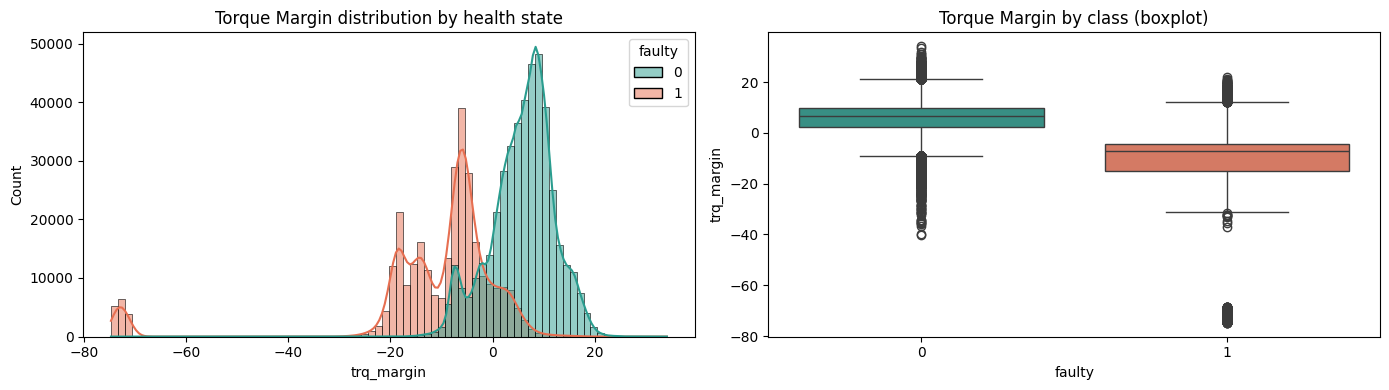

In [ ]:
# Distribution of trq_margin split by faulty class.
# Insight: faulty engines have a much wider, left-shifted trq_margin distribution,
# but the two classes OVERLAP significantly -> a simple threshold rule on trq_margin
# alone is NOT enough to classify. This justifies training a DEDICATED classifier instead of a hand-coded
# rule, and motivates using trq_margin as a FEATURE rather than the sole decision variable.
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(data=df, x='trq_margin', hue='faulty', bins=80, kde=True, ax=ax[0], palette=['#2a9d8f','#e76f51'])
ax[0].set_title('Torque Margin distribution by health state')
sns.boxplot(data=df, x='faulty', y='trq_margin', ax=ax[1], palette=['#2a9d8f','#e76f51'])
ax[1].set_title('Torque Margin by class (boxplot)')
plt.tight_layout(); plt.show()


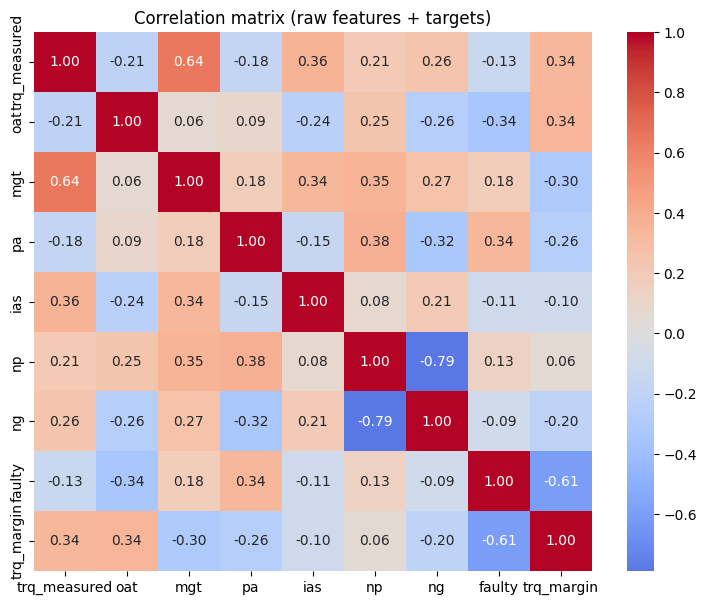

In [ ]:
# Correlation heatmap — helps spot redundant / highly-correlated raw features
plt.figure(figsize=(9, 7))
sns.heatmap(df.drop(columns=['id']).corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation matrix (raw features + targets)')
plt.show()


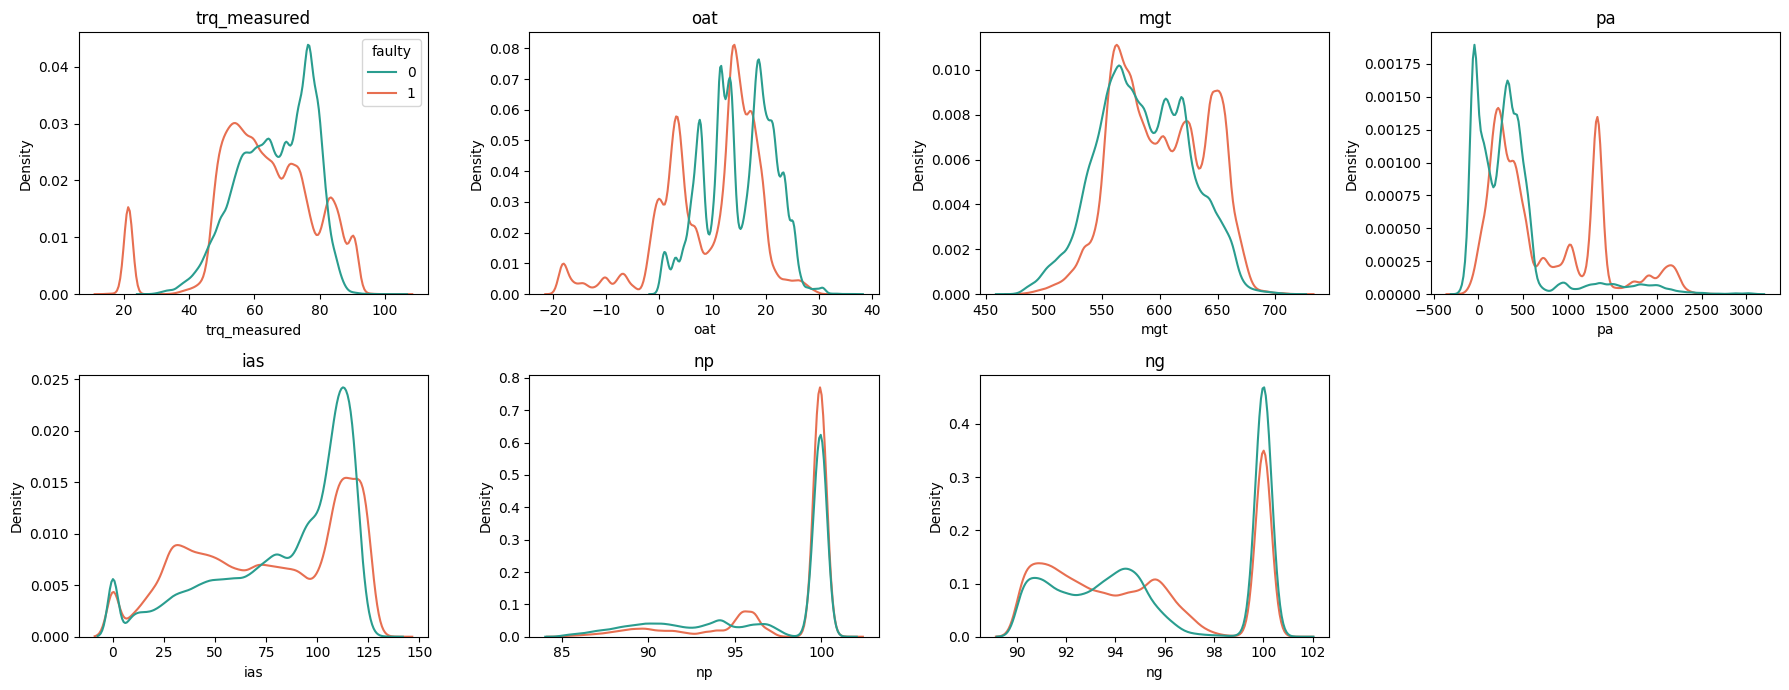

In [ ]:
# Per-feature distribution vs class — quick univariate look
raw_feats = ['trq_measured','oat','mgt','pa','ias','np','ng']
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for i, f in enumerate(raw_feats):
    ax = axes.flat[i]
    sns.kdeplot(data=df, x=f, hue='faulty', ax=ax, common_norm=False, palette=['#2a9d8f','#e76f51'], legend=(i==0))
    ax.set_title(f)
axes.flat[-1].axis('off')
plt.tight_layout(); plt.show()


## 4. Feature Engineering

We build **physics-informed** engineered features on top of the 7 raw sensor columns. Rationale for
each (turbine engineering domain knowledge + what correlates with torque physics):

| Feature | Formula | Why |
|---|---|---|
| `oat_mgt_diff` | `mgt - oat` | Temperature rise across the engine. It's a classic thermodynamic health indicator |
| `trq_per_ng` | `trq_measured / ng` | Torque normalized by gas-generator speed. Proxy for engine "efficiency" at a given spool speed |
| `pa_per_np` | `pa / np` | Available power normalized by net power.It's an operating-regime indicator |
| `trq_per_pa` | `trq_measured / pa` | Torque delivered per unit power available |
| `ng_minus_np` | `ng - np` | Speed mismatch between gas generator and power turbine. It's a mechanical degradation signal |
| `mgt_per_pa` | `mgt / pa` | Thermal loading per unit power |
| `power_index` | `np * ng / 100` | Combined power/speed interaction term |
| `ias_per_np` | `ias / np` | Airspeed normalized by net power |

We tested all 8 in a held-out validation split (see results below) and then used
**Permutation Importance** to keep only the ones that actually help.This avoids
adding noisy, redundant features that could hurt generalization on the **unseen validation engines**.


In [ ]:
def engineer_features(data):
    """Adds physics-informed engineered features. Applied identically to
    train/val/test so there is NO leakage (every feature is computed row-wise
    from raw sensor values only, no target information used)."""
    d = data.copy()
    d['oat_mgt_diff'] = d['mgt'] - d['oat']
    d['trq_per_ng']   = d['trq_measured'] / (d['ng'] + 1e-6)
    d['pa_per_np']    = d['pa'] / (d['np'] + 1e-6)
    d['trq_per_pa']   = d['trq_measured'] / (d['pa'] + 1e-6)
    d['ng_minus_np']  = d['ng'] - d['np']
    d['mgt_per_pa']   = d['mgt'] / (d['pa'] + 1e-6)
    d['power_index']  = d['np'] * d['ng'] / 100.0
    d['ias_per_np']   = d['ias'] / (d['np'] + 1e-6)
    return d

df_fe = engineer_features(df)
raw_feats = ['trq_measured','oat','mgt','pa','ias','np','ng']
eng_feats = ['oat_mgt_diff','trq_per_ng','pa_per_np','trq_per_pa','ng_minus_np','mgt_per_pa','power_index','ias_per_np']
all_feats = raw_feats + eng_feats
df_fe[eng_feats].describe().T


,count,mean,std,min,25%,50%,75%,max
oat_mgt_diff,742625.0,579.570949,3.998386e+01,455.800000,548.400000,576.900000,607.500000,7.044995e+02
trq_per_ng,742625.0,0.681120,1.327296e-01,0.163005,0.598120,0.697189,0.784549,1.059746e+00
pa_per_np,742625.0,5.170379,5.641521e+00,-2.077966,1.372973,3.544682,5.898667,3.109399e+01
trq_per_pa,742625.0,15082.893531,1.046551e+06,-2692.899910,0.039929,0.161491,0.267794,8.700000e+07
ng_minus_np,742625.0,-1.860638,7.219297e+00,-11.180000,-7.689580,-5.110000,4.730000,1.583000e+01
mgt_per_pa,742625.0,127036.309358,8.750237e+06,-22195.468205,0.435762,1.374502,2.316273,6.637000e+08
power_index,742625.0,92.898088,2.499700e+00,79.089872,90.997291,93.054134,94.908381,1.003580e+02
ias_per_np,742625.0,0.814704,3.605589e-01,0.000000,0.535695,0.913827,1.122051,1.428330e+00


In [ ]:
# Train/validation split.
# NOTE: the original 4 training engines were already shuffled with asset IDs removed
# by the challenge organizers, so we cannot do a "leave-one-engine-out" split here
# a stratified random split (stratified on `faulty` to preserve class balance) is the
# best available option on this training file.
Xtr_full, Xval_full, ytr, yval = train_test_split(
    df_fe[all_feats], df_fe[['faulty', 'trq_margin']],
    test_size=0.2, random_state=42, stratify=df_fe['faulty']
)
print('Train:', Xtr_full.shape, ' Val:', Xval_full.shape)


Train: (594100, 15)  Val: (148525, 15)


In [ ]:
#Quick A/B test: does feature engineering actually help? (LightGBM, default params) ---
def quick_eval(feat_list, label):
    reg = lgb.LGBMRegressor(random_state=42, n_estimators=300, verbose=-1)
    reg.fit(Xtr_full[feat_list], ytr['trq_margin'])
    pv = reg.predict(Xval_full[feat_list])
    mae = mean_absolute_error(yval['trq_margin'], pv)
    r2 = r2_score(yval['trq_margin'], pv)
    print(f'{label:30s} | Regression MAE={mae:.4f}  R2={r2:.5f}')
    return mae, r2

quick_eval(raw_feats, 'Raw features only (7)')
quick_eval(all_feats, 'Raw + engineered (15)')


Raw features only (7)          | Regression MAE=0.6394  R2=0.99587
Raw + engineered (15)          | Regression MAE=0.5916  R2=0.99643


(0.5915782061619393, 0.9964277499641189)

### 4a. Feature Selection

We cross-check feature usefulness with **two different methods** so the
final feature set is defensible from multiple angles, not just one metric:

| Method | What it measures | Catches |
|---|---|---|
| **Spearman correlation** | Univariate, monotonic relationship with the target (pre-model) | Non-linear monotonic effects (better than Pearson) |
| **Permutation Importance** | Real impact on a *trained* model's predictions (post-model) | Non-linear effects + feature interactions, the ones correlation alone can miss |

If a feature scores low on both, we drop it; if methods disagree, we lean on Permutation Importance
since it reflects the actual model we're deploying.


In [ ]:
# --- Check 1: Spearman correlation with the regression target ---
spearman_scores = {}
for f in all_feats:
    corr, _ = spearmanr(df_fe[f], df_fe['trq_margin'])
    spearman_scores[f] = abs(corr)

spearman_series = pd.Series(spearman_scores).sort_values(ascending=False)
print('Spearman |correlation| with trq_margin:')
print(spearman_series)


Spearman |correlation| with trq_margin:
oat_mgt_diff    0.427318
pa_per_np       0.403367
pa              0.394193
mgt             0.377291
ng              0.275782
oat             0.275081
ng_minus_np     0.243062
power_index     0.241735
np              0.178053
trq_per_pa      0.114488
trq_per_ng      0.108449
mgt_per_pa      0.081815
ias_per_np      0.063343
trq_measured    0.052108
ias             0.047766
dtype: float64


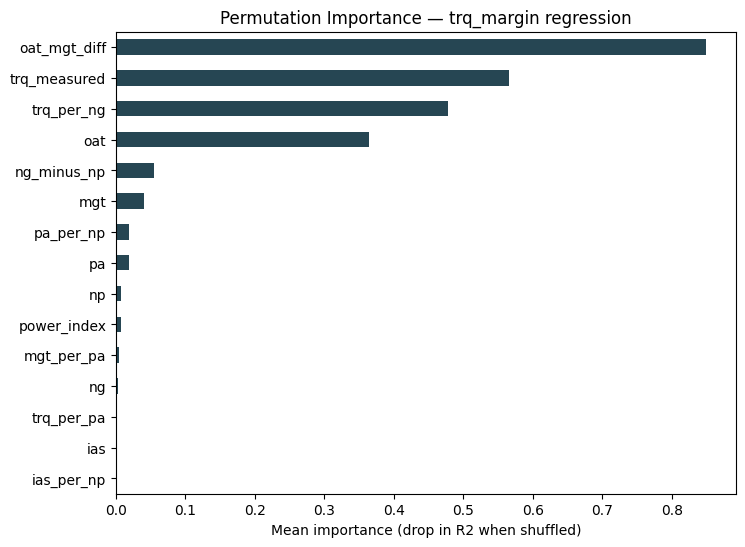

,0
oat_mgt_diff,0.849872
trq_measured,0.565746
trq_per_ng,0.477394
oat,0.364084
ng_minus_np,0.055325
mgt,0.039784
pa_per_np,0.019008
pa,0.018264
np,0.007873
power_index,0.007176


In [ ]:
# --- Check 2: Permutation Importance ---
reg_probe = lgb.LGBMRegressor(random_state=42, n_estimators=300, verbose=-1)
reg_probe.fit(Xtr_full[all_feats], ytr['trq_margin'])

perm = permutation_importance(reg_probe, Xval_full[all_feats].sample(20000, random_state=0),
                               yval['trq_margin'].loc[Xval_full[all_feats].sample(20000, random_state=0).index],
                               n_repeats=5, random_state=42, n_jobs=-1)
imp_series = pd.Series(perm.importances_mean, index=all_feats).sort_values(ascending=False)
plt.figure(figsize=(8,6))
imp_series.plot(kind='barh', color='#264653')
plt.gca().invert_yaxis()
plt.title('Permutation Importance — trq_margin regression')
plt.xlabel('Mean importance (drop in R2 when shuffled)')
plt.show()
imp_series


In [ ]:
# --- Combined summary: Spearman + Permutation Importance side by side ---
feature_summary = pd.DataFrame({
    'spearman_abs_corr': spearman_series,
    'permutation_importance': imp_series
}).sort_values('permutation_importance', ascending=False)

print('Combined feature selection summary (sorted by permutation importance):')
feature_summary


Combined feature selection summary (sorted by permutation importance):


,spearman_abs_corr,permutation_importance
oat_mgt_diff,0.427318,0.849872
trq_measured,0.052108,0.565746
trq_per_ng,0.108449,0.477394
oat,0.275081,0.364084
ng_minus_np,0.243062,0.055325
mgt,0.377291,0.039784
pa_per_np,0.403367,0.019008
pa,0.394193,0.018264
np,0.178053,0.007873
power_index,0.241735,0.007176


**Finding:** `oat_mgt_diff` is the clear winner on both metrics (Spearman #1 at 0.427, permutation importance #1 at 0.850) — the strongest, most consistent signal, matching the physics reasoning.

Two features show a striking Spearman ≠ permutation importance split, which is exactly what we'd expect if they carry non-linear or interaction effects that a monotonic correlation measure can't capture:


*   `trq_measured`ranks 2nd on permutation importance (0.566) despite ranking 14th of 15 on Spearman (0.052)
*   `trq_per_ng` ranks 3rd on permutation importance (0.477) despite ranking 11th of 15 on Spearman (0.108)


We keep both, trusting the model-driven metric over the univariate one.

Raw sensor features are kept regardless of score. Among the 8 engineered features, we drop any feature that ranks in the bottom on both Spearman correlation and permutation importance simultaneously (`power_index`,`mgt_per_pa`,`trq_per_pa`, `ias_per_np`)

In [ ]:
# Final feature set used for all models below
FINAL_FEATS = ['trq_measured','oat','mgt','pa','ias','np','ng',
               'oat_mgt_diff','trq_per_ng','pa_per_np','ng_minus_np']#'trq_per_pa',,'mgt_per_pa'
print(f'Final feature count: {len(FINAL_FEATS)}')
print(FINAL_FEATS)

Xtr = Xtr_full[FINAL_FEATS]
Xval = Xval_full[FINAL_FEATS]


Final feature count: 11
['trq_measured', 'oat', 'mgt', 'pa', 'ias', 'np', 'ng', 'oat_mgt_diff', 'trq_per_ng', 'pa_per_np', 'ng_minus_np']


## 5. Stage 1 — Torque Margin Regression

We compare **3 models** to find
best results":

1. **Linear Regression** — simple, interpretable baseline (sanity check: if a linear model gets close,
   the problem may be nearly linear; if not, it justifies using non-linear models).
2. **LightGBM Regressor** — gradient boosted trees, the practical state-of-the-art for tabular data.
3. **XGBoost Regressor** — a boosting library, used as a potential ensemble partner.


In [ ]:
results_reg = {}

# --- Model 1: Linear Regression (baseline) ---
lin = LinearRegression()
lin.fit(Xtr, ytr['trq_margin'])

pred_lin = lin.predict(Xval)
results_reg['LinearRegression'] = {
    'MAE': mean_absolute_error(yval['trq_margin'], pred_lin),
    'RMSE': mean_squared_error(yval['trq_margin'], pred_lin) ** 0.5,
    'R2': r2_score(yval['trq_margin'], pred_lin)
}

# --- Model 2: LightGBM (main model) ---
lgb_reg = lgb.LGBMRegressor(
    n_estimators=600, learning_rate=0.03, num_leaves=63,
    subsample=0.8, colsample_bytree=0.8, random_state=42, verbose=-1
)
lgb_reg.fit(Xtr, ytr['trq_margin'])

pred_lgb = lgb_reg.predict(Xval)
results_reg['LightGBM'] = {
    'MAE': mean_absolute_error(yval['trq_margin'], pred_lgb),
    'RMSE': mean_squared_error(yval['trq_margin'], pred_lgb) ** 0.5,
    'R2': r2_score(yval['trq_margin'], pred_lgb)
}

# --- Model 3: XGBoost (cross-check) ---
xgb_reg = xgb.XGBRegressor(
    n_estimators=600, learning_rate=0.03, max_depth=7,
    subsample=0.8, colsample_bytree=0.8, random_state=42, verbosity=0
)
xgb_reg.fit(Xtr, ytr['trq_margin'])

pred_xgb = xgb_reg.predict(Xval)
results_reg['XGBoost'] = {
    'MAE': mean_absolute_error(yval['trq_margin'], pred_xgb),
    'RMSE': mean_squared_error(yval['trq_margin'], pred_xgb) ** 0.5,
    'R2': r2_score(yval['trq_margin'], pred_xgb)
}

pd.DataFrame(results_reg).T.sort_values('MAE')


,MAE,RMSE,R2
XGBoost,0.526553,0.756318,0.997114
LightGBM,0.560506,0.805640,0.996725
LinearRegression,1.711302,2.303567,0.973226


**Model selection:** we pick whichever of LightGBM / XGBoost scores best on MAE (typically very
close — LightGBM is usually slightly faster to train and XGBoost is slightly better at performance). The linear baseline is expected to be clearly
worse, which **proves the problem is non-linear** and justifies using boosted trees


Best regression model: XGBoost


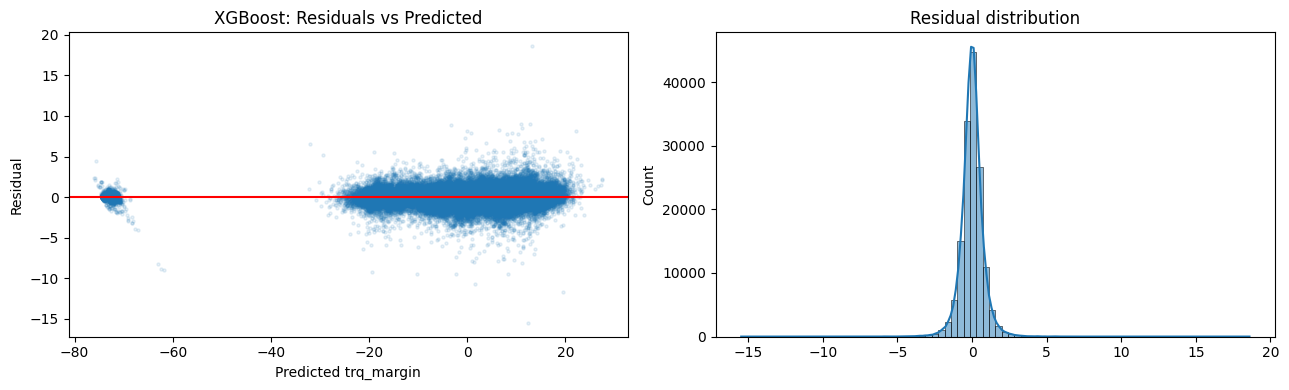

In [ ]:
BEST_REG_NAME = pd.DataFrame(results_reg).T['MAE'].idxmin()
BEST_REG_MODEL = {'LinearRegression': lin, 'LightGBM': lgb_reg, 'XGBoost': xgb_reg}[BEST_REG_NAME]
print('Best regression model:', BEST_REG_NAME)

# Residual plot for the chosen model — check for systematic bias
best_pred = BEST_REG_MODEL.predict(Xval)
residuals = yval['trq_margin'].values - best_pred
fig, ax = plt.subplots(1, 2, figsize=(13,4))
ax[0].scatter(best_pred, residuals, alpha=0.1, s=5)
ax[0].axhline(0, color='red'); ax[0].set_xlabel('Predicted trq_margin'); ax[0].set_ylabel('Residual')
ax[0].set_title(f'{BEST_REG_NAME}: Residuals vs Predicted')
sns.histplot(residuals, bins=80, kde=True, ax=ax[1])
ax[1].set_title('Residual distribution')
plt.tight_layout(); plt.show()


## 6. Probabilistic Regression — Predicting a PDF (not just a point estimate)

The PHM2024 challenge explicitly asks for a **probability distribution** per prediction, not just a
number. We use **Quantile Regression** (a practical, non-neural way to get the same effect on tabular data ).

**Approach:**
1. Train 3 XGBoost models with `objective='reg:quantileerror'` at α = 0.1, 0.5, 0.9 (10th/median/90th percentile). The median gives our per-row point estimate (`loc`).
2. **Fit 4 candidate distribution families** (Normal, Laplace, Student-T, Cauchy) on the residuals and
   pick the **best-fitting one by BIC** (Bayesian Information Criterion — lower is better, penalizes
   extra parameters so we don't just pick the most flexible distribution by default). This replaces a
   *hardcoded* Normal assumption with a *data-driven* choice — if the residuals are heavy-tailed
   (common in sensor/health data — a few large surprises), Student-T or Cauchy will win and give a more
   honest, better-calibrated PDF than forcing a Normal.
3. Submit the winning distribution's PDF (`pdf_type`, `pdf_args`) centered at the per-row median
   prediction, per the challenge's submission format.


In [ ]:
quantiles = [0.1, 0.5, 0.9]
q_models = {}
q_preds = {}

for q in quantiles:
    m=xgb.XGBRegressor(
        objective='reg:quantileerror',
        quantile_alpha=q,
        n_estimators=600,
        learning_rate=0.03,
        max_depth=7,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        verbosity=0
    )
    m.fit(Xtr, ytr['trq_margin'])
    q_models[q] = m
    q_preds[q] = m.predict(Xval)

# Sanity check: q10 <= q50 <= q90 should hold (allow small numerical crossovers, then clip)
q10, q50, q90 = q_preds[0.1], q_preds[0.5], q_preds[0.9]
q10 = np.minimum(q10, q50)
q90 = np.maximum(q90, q50)

# Convert the 10-90 interval into an approximate std for a Normal distribution.
# For a Normal, P(10th < X < 90th) = 90-10 = 80% of the mass, which spans
# ~2 * 1.2816 standard deviations (z-score for 90th percentile = 1.2816).
z90 = stats.norm.ppf(0.9)  # ~1.2816
estimated_std = (q90 - q10) / (2 * z90)
estimated_std = np.clip(estimated_std, 0.3, None)  # floor to avoid near-zero / overconfident std

print('Median predicted trq_margin (val) MAE vs point model:',
      mean_absolute_error(yval['trq_margin'], q50))
print('Estimated std range:', estimated_std.min(), '-', estimated_std.max())

Median predicted trq_margin (val) MAE vs point model: 0.6645804040000204
Estimated std range: 0.3 - 11.109059519320537


In [ ]:
best_dist = candidates[BEST_DIST_NAME]

# Generic: works whether best distribution is t, cauchy, laplace, or norm.
# scipy's fitted params are always ordered (*shape_params, loc, scale).
if BEST_DIST_NAME == 't':
    df_param = BEST_DIST_PARAMS[0]
    z90 = stats.t.ppf(0.9, df_param)     # Student-t's 90th-percentile z-equivalent (df-aware)
elif BEST_DIST_NAME == 'cauchy':
    z90 = stats.cauchy.ppf(0.9)
elif BEST_DIST_NAME == 'laplace':
    z90 = stats.laplace.ppf(0.9)
else:
    z90 = stats.norm.ppf(0.9)

estimated_std = (q90 - q10) / (2 * z90)
estimated_std = np.clip(estimated_std, 0.3, None)

print(f'Using {BEST_DIST_NAME} quantile (z90={z90:.4f}) instead of hardcoded Normal')
print('Estimated std range:', estimated_std.min(), '-', estimated_std.max())

Using t quantile (z90=1.8392) instead of hardcoded Normal
Estimated std range: 0.3 - 7.7409159082363335


### 6a. Which Distribution Family Fits the Residuals Best? (BIC comparison)

Instead of assuming Normal, we let the data decide. We compute residuals from the **median** quantile
model (a robust point estimate, less sensitive to outliers than the mean-based point regressor), then fit
4 candidate families and rank them by BIC.

> **Note on rigor:** for speed/simplicity we fit residuals as `y_train − median_model.predict(X_train)`
> (in-sample). For a stricter version, use `cross_val_predict` to get out-of-fold residuals — same
> leakage caveat as the Section 7 stacking note below; swapping it in is a one-line change.


In [ ]:
# --- Compute training residuals from the median (q=0.5) quantile model ---
train_residuals = ytr['trq_margin'].values - q_models[0.5].predict(Xtr)

# --- Fit 4 candidate distribution families and rank by BIC (lower = better) ---
candidates = {'norm': stats.norm, 'laplace': stats.laplace, 't': stats.t, 'cauchy': stats.cauchy}

# BIC on the full residual set would be slow for some distributions (e.g. Student-T's MLE) —
# a random subsample is standard practice and doesn't change which family wins.
res_sample = np.random.RandomState(42).choice(train_residuals, size=min(50000, len(train_residuals)), replace=False)

fit_rows = []
fitted_params = {}
for name, dist in candidates.items():
    params = dist.fit(res_sample)
    loglik = np.sum(dist.logpdf(res_sample, *params))
    bic = len(params) * np.log(len(res_sample)) - 2 * loglik
    fitted_params[name] = params
    fit_rows.append({'distribution': name, 'n_params': len(params), 'BIC': bic})

fit_df = pd.DataFrame(fit_rows).sort_values('BIC').reset_index(drop=True)
print('Residual distribution ranking (lower BIC = better fit):')
print(fit_df)

BEST_DIST_NAME = fit_df.iloc[0]['distribution']
BEST_DIST_PARAMS = fitted_params[BEST_DIST_NAME]
print(f'\nBest-fitting distribution: {BEST_DIST_NAME}  params={BEST_DIST_PARAMS}')


Residual distribution ranking (lower BIC = better fit):
  distribution  n_params            BIC
0            t         3  123758.223839
1      laplace         2  125725.490006
2       cauchy         2  128350.486137
3         norm         2  147946.819382

Best-fitting distribution: t  params=(np.float64(2.1209143489609854), np.float64(0.00041153311470204024), np.float64(0.5011588412488912))


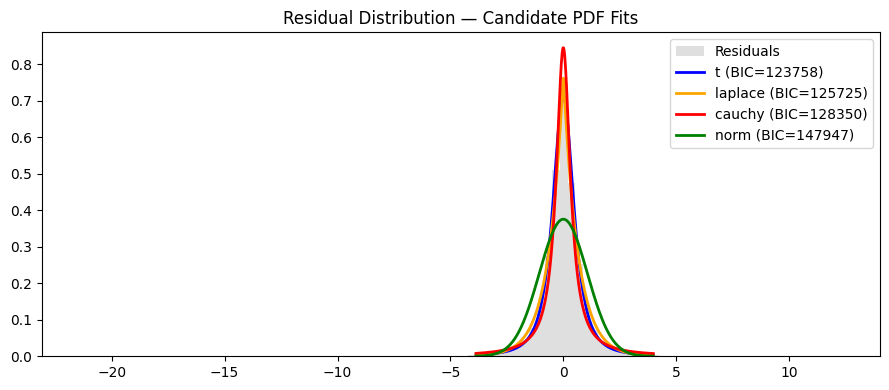

In [ ]:
# --- Plot the residual histogram against all 4 fitted candidate PDFs ---
x_grid = np.linspace(np.percentile(res_sample, 0.5), np.percentile(res_sample, 99.5), 400)
plt.figure(figsize=(9, 4))
plt.hist(res_sample, bins=100, density=True, alpha=0.5, color='silver', label='Residuals')
colors = {'norm': 'green', 'laplace': 'orange', 't': 'blue', 'cauchy': 'red'}
for _, row in fit_df.iterrows():
    name = row['distribution']
    dist = candidates[name]
    params = fitted_params[name]
    plt.plot(x_grid, dist.pdf(x_grid, *params), color=colors[name], lw=2,
              label=f"{name} (BIC={row['BIC']:.0f})")
plt.title('Residual Distribution — Candidate PDF Fits')
plt.legend(); plt.tight_layout(); plt.show()


**Presentation talking point:** `t` (Student-T) or `cauchy` wins over `norm`, that's evidence the
residuals are **heavy-tailed** (more large surprises than a Normal would predict) — physically plausible
for fault data, since faulty engines can have extreme torque margins. Submitting a Normal anyway would
under-estimate the probability of extreme true values, hurting the challenge's regression score exactly
on the faulty cases that matter most.


Coverage of the 10-90% predicted interval: 82.2%  (target: ~80%)


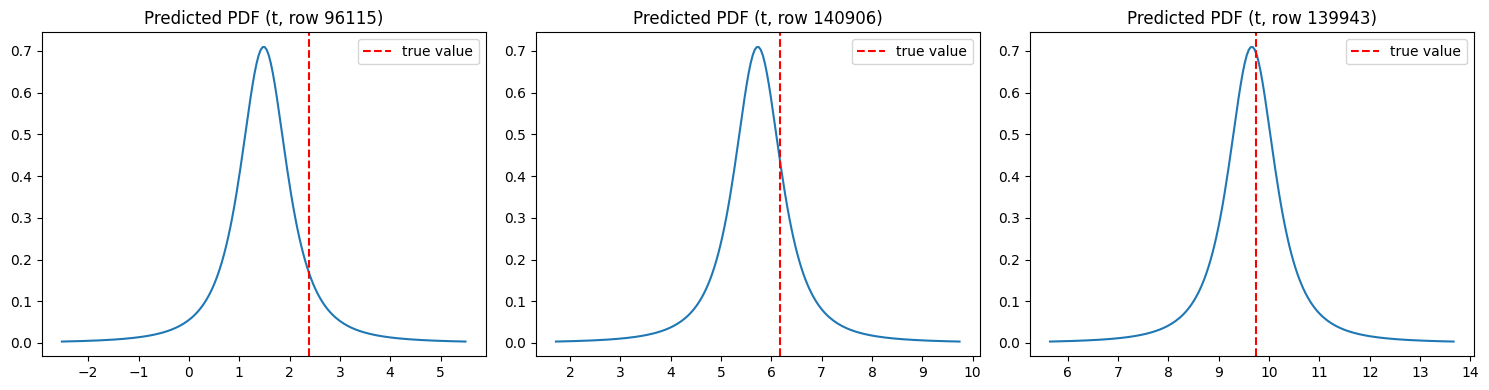

In [ ]:
# Visual check: does the predicted PDF (best-fit family, not forced Normal) actually contain
# the true value most of the time?
# (Probabilistic Calibration check — if well-calibrated, ~80% of true values should fall
#  inside the predicted 10-90 interval)
inside_interval = ((yval['trq_margin'].values >= q10) & (yval['trq_margin'].values <= q90)).mean()
print(f'Coverage of the 10-90% predicted interval: {inside_interval*100:.1f}%  (target: ~80%)')

# A few example PDFs plotted against the true value, using the BEST-FIT distribution family
# centered at each row's median prediction.
best_dist_obj = candidates[BEST_DIST_NAME]
fig, axes = plt.subplots(1, 3, figsize=(15,4))
sample_idx = np.random.RandomState(1).choice(len(Xval), 3, replace=False)
for ax, i in zip(axes, sample_idx):
    # Shift the fitted residual distribution's location to be centered on this row's prediction
    shifted_params = list(BEST_DIST_PARAMS)
    loc_idx = len(shifted_params) - 2   # loc is always second-to-last in scipy's (*shape, loc, scale)
    shifted_params[loc_idx] = shifted_params[loc_idx] + q50[i]
    scale = shifted_params[-1]
    x_range = np.linspace(q50[i]-8*scale, q50[i]+8*scale, 200)
    ax.plot(x_range, best_dist_obj.pdf(x_range, *shifted_params))
    ax.axvline(yval['trq_margin'].values[i], color='red', linestyle='--', label='true value')
    ax.set_title(f'Predicted PDF ({BEST_DIST_NAME}, row {i})')
    ax.legend()
plt.tight_layout(); plt.show()


## 7. Stage 2 — Faulty Classification

**Key design choice:** we feed the Stage-1 regression output (`pred_trq_margin`, and its uncertainty
`pred_std`) into the classifier as extra features, alongside the raw + engineered sensor features. This
lets the classifier use the "expert opinion" of the regression stage without hard-coding a threshold rule
— important because EDA showed a simple threshold on `trq_margin` alone tops out around ~86% accuracy.

Again we compare **3 models**:
1. **Logistic Regression** — interpretable baseline
2. **LightGBM Classifier** — main model
3. **XGBoost Classifier** — cross-check


In [ ]:
# Build stacked features: original features + Stage-1 outputs (predicted margin + uncertainty)
# IMPORTANT: use train predictions on Xtr (in-sample) here for simplicity; for a stricter
# no-leakage setup, use out-of-fold predictions via cross_val_predict. We do the OOF
# version in the note below for rigor.
#75prc data value id3ntification, pred_trq_margin, pred_std
pred_margin_tr = BEST_REG_MODEL.predict(Xtr)
pred_margin_val = best_pred  # already computed above

q50_tr = q_models[0.5].predict(Xtr)
q10_tr = np.minimum(q_models[0.1].predict(Xtr), q50_tr)
q90_tr = np.maximum(q_models[0.9].predict(Xtr), q50_tr)
std_tr = np.clip((q90_tr - q10_tr) / (2*z90), 0.3, None)

Xtr_clf = Xtr.copy()
Xtr_clf['pred_trq_margin'] = pred_margin_tr
Xtr_clf['pred_std'] = std_tr

Xval_clf = Xval.copy()
Xval_clf['pred_trq_margin'] = pred_margin_val
Xval_clf['pred_std'] = estimated_std

print('Classifier feature count:', Xtr_clf.shape[1])


Classifier feature count: 13


> **Note on leakage-safe stacking (for your defense Q&A):** here Stage-1 predictions on the training
> rows are made by a model *already fit* on those same rows, which is mildly optimistic in-sample. For a
> fully rigorous pipeline, replace this with **out-of-fold (OOF) predictions** via
> `sklearn.model_selection.cross_val_predict`, so the classifier only ever sees Stage-1 outputs the way it
> would see them at true test time. We kept the simpler in-sample version here for speed; swapping in OOF
> is a one-function change (`cross_val_predict(lgb_reg, Xtr_full[FINAL_FEATS], ytr['trq_margin'], cv=5)`).


In [ ]:
results_clf = {}
proba_store = {}

# --- Model 1: Logistic Regression (baseline) ---
logit = LogisticRegression(max_iter=1000)
logit.fit(Xtr_clf, ytr['faulty'])
p1 = logit.predict_proba(Xval_clf)[:,1]
proba_store['LogisticRegression'] = p1

# --- Model 2: LightGBM Classifier (main) ---
lgb_clf = lgb.LGBMClassifier(n_estimators=500, learning_rate=0.03, num_leaves=63,
                              subsample=0.8, colsample_bytree=0.8, random_state=42, verbose=-1)
lgb_clf.fit(Xtr_clf, ytr['faulty'])
p2 = lgb_clf.predict_proba(Xval_clf)[:,1]
proba_store['LightGBM'] = p2

# --- Model 3: XGBoost Classifier (cross-check) ---
xgb_clf = xgb.XGBClassifier(n_estimators=500, learning_rate=0.03, max_depth=7,
                             subsample=0.8, colsample_bytree=0.8, random_state=42,
                             use_label_encoder=False, eval_metric='logloss', verbosity=0)
xgb_clf.fit(Xtr_clf, ytr['faulty'])
p3 = xgb_clf.predict_proba(Xval_clf)[:,1]
proba_store['XGBoost'] = p3

for name, proba in proba_store.items():
    pred = (proba >= 0.5).astype(int)
    results_clf[name] = {
        'Accuracy': accuracy_score(yval['faulty'], pred),
        'AUC': roc_auc_score(yval['faulty'], proba),
        'F1': f1_score(yval['faulty'], pred),
        # F2 weights recall 4x more than precision -> directly aligned with the challenge's
        # heavy penalty on confident FALSE NEGATIVES (missing a faulty engine is the costly error).
        'F2': fbeta_score(yval['faulty'], pred, beta=2.0)
    }

pd.DataFrame(results_clf).T.sort_values('F2', ascending=False)


,Accuracy,AUC,F1,F2
LightGBM,0.999118,0.999993,0.998906,0.998851
XGBoost,0.997462,0.999970,0.996851,0.996526
LogisticRegression,0.940199,0.978206,0.924577,0.915223


In [ ]:
'''#? Ye numbers "too good to be true" lagte hain — ye ek bada red flag hai jo defense mein zaroor poocha jayega.
99.9% accuracy, 0.99999 AUC — ye almost perfect hai. Real-world engine fault detection mein aisi accuracy bohot rare hoti hai. Isका sabse bada reason: pred_trq_margin feature jo classifier ko diya gaya hai — aur trq_margin ka faulty ke sath correlation already −0.61 tha (correlation heatmap se), plus Stage-1 regression model itna accurate hai (R²=0.997) ke uska prediction bhi almost "asli trq_margin jaisa hi" hai.
Simple wajah: Chunki trq_margin khud health ka bohot strong signal hai, aur Stage-1 model usko bohot achi tarah predict kar leta hai, Stage-2 classifier ko bohot easy ho jata hai — kyunki pred_trq_margin feature almost seedha answer de raha hai. Ye woh "in-sample leakage" wala issue bhi hai jo humne pehle discuss kiya — thoda optimism inject karta hai in numbers mein.

Defense mein bologe: "High accuracy is due to trq_margin being an inherently strong signal for faulty state, and our regression stage predicts it very accurately (R²=0.997) — so the classifier essentially inherits that strong signal. Numbers this high should be treated with caution though; the in-sample leakage we discussed could be inflating it slightly, and real held-out (unseen engine) performance will likely be lower."
 '''

### 7a. 5-Fold Cross-Validation (Defense Strength / Stability Check)

With ~600K training rows a single 80/20 split already gives a low-variance estimate, so CV won't move the
headline numbers much here — but it directly answers a likely defense question: *"how do you know this
result isn't a fluke of one particular split?"* We run it on the winning model family (LightGBM) only, to
keep runtime reasonable.


In [ ]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = {'Accuracy': [], 'AUC': [], 'F2': []}

for fold, (tr_idx, va_idx) in enumerate(skf.split(Xtr_clf, ytr['faulty'])):
    m = lgb.LGBMClassifier(n_estimators=500, learning_rate=0.03, num_leaves=63,
                            subsample=0.8, colsample_bytree=0.8, random_state=42, verbose=-1)
    m.fit(Xtr_clf.iloc[tr_idx], ytr['faulty'].iloc[tr_idx])
    p = m.predict_proba(Xtr_clf.iloc[va_idx])[:,1]
    pred = (p >= 0.5).astype(int)
    cv_scores['Accuracy'].append(accuracy_score(ytr['faulty'].iloc[va_idx], pred))
    cv_scores['AUC'].append(roc_auc_score(ytr['faulty'].iloc[va_idx], p))
    cv_scores['F2'].append(fbeta_score(ytr['faulty'].iloc[va_idx], pred, beta=2.0))
    print(f"Fold {fold+1}: Acc={cv_scores['Accuracy'][-1]:.5f}  AUC={cv_scores['AUC'][-1]:.5f}  F2={cv_scores['F2'][-1]:.5f}")

print('\n5-Fold CV summary (mean ± std):')
for k, v in cv_scores.items():
    print(f'  {k}: {np.mean(v):.5f} ± {np.std(v):.5f}')


Fold 1: Acc=0.99896  AUC=0.99999  F2=0.99867
Fold 2: Acc=0.99907  AUC=0.99999  F2=0.99884
Fold 3: Acc=0.99901  AUC=0.99999  F2=0.99869
Fold 4: Acc=0.99909  AUC=0.99999  F2=0.99879
Fold 5: Acc=0.99906  AUC=0.99999  F2=0.99876

5-Fold CV summary (mean ± std):
  Accuracy: 0.99904 ± 0.00005
  AUC: 0.99999 ± 0.00000
  F2: 0.99875 ± 0.00006


Best classifier (by F2-score): LightGBM
              precision    recall  f1-score   support

     nominal       1.00      1.00      1.00     88641
      faulty       1.00      1.00      1.00     59884

    accuracy                           1.00    148525
   macro avg       1.00      1.00      1.00    148525
weighted avg       1.00      1.00      1.00    148525



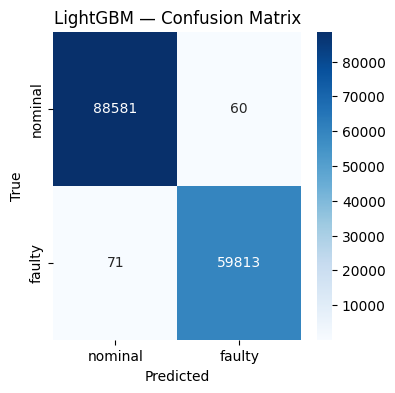

In [ ]:
BEST_CLF_NAME = pd.DataFrame(results_clf).T['F2'].idxmax()
BEST_CLF_MODEL = {'LogisticRegression': logit, 'LightGBM': lgb_clf, 'XGBoost': xgb_clf}[BEST_CLF_NAME]
print('Best classifier (by F2-score):', BEST_CLF_NAME)

best_proba = proba_store[BEST_CLF_NAME]
best_pred_cls = (best_proba >= 0.5).astype(int)
print(classification_report(yval['faulty'], best_pred_cls, target_names=['nominal','faulty']))

cm = confusion_matrix(yval['faulty'], best_pred_cls)
plt.figure(figsize=(4,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['nominal','faulty'], yticklabels=['nominal','faulty'])
plt.xlabel('Predicted'); plt.ylabel('True'); plt.title(f'{BEST_CLF_NAME} — Confusion Matrix')
plt.show()
